# **Intro to Generative AI for Engineers**

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# 📖 TABLE OF CONTENTS

- [What is Artificial Intelligence?](#What-is-Artificial-Intelligence?)
  - [Machine Learning](#Machine-Learning)
  - [Generative AI](#Generative-AI)
  - [Agentic AI](#Agentic-AI)
  - [AI vs Deterministic Code](#AI-vs-Deterministic-Code)
- [Key Terminology](#Key-Terminology)
  - [Large Language Model (LLM)](#Large-Language-Model-(LLM))
  - [Tokens](#Tokens)
  - [Hallucination](#Hallucination)
  - [Retrieval-Augmented Generation (RAG)](#Retrieval-Augmented-Generation-(RAG))
  - [Context Window](#Context-Window)
  - [Temperature](#Temperature)
- [How LLMs Work](#How-LLMs-Work)
  - [Pre-training](#Pre-training)
  - [Fine-tuning and RLHF](#Fine-tuning-and-RLHF)
  - [Inference](#Inference)
  - [Prompt as Function](#Prompt-as-Function)
- [Engineering Use Cases](#Engineering-Use-Cases)
  - [Code and Tests](#Code-and-Tests)
  - [Review and Debug](#Review-and-Debug)
  - [Documentation](#Documentation)
  - [Refactor and Migration](#Refactor-and-Migration)
  - [What AI Should Not Own](#What-AI-Should-Not-Own)
- [Prompt Engineering - the RCTFV Framework](#Prompt-Engineering---the-RCTFV-Framework)
  - [Role](#Role)
  - [Context](#Context)
  - [Task](#Task)
  - [Format](#Format)
  - [Verification](#Verification)
  - [Worked Example](#Worked-Example)
  - [Common Mistakes](#Common-Mistakes)
- [Data Safety & Responsible Use](#Data-Safety-&-Responsible-Use)
  - [Never-share Tier](#Never-share-Tier)
  - [Caution Tier](#Caution-Tier)
  - [Safe Tier](#Safe-Tier)
  - [Enterprise Protections](#Enterprise-Protections)
  - [Daily Habit Checklist](#Daily-Habit-Checklist)
- [Model Choice & Cost](#Model-Choice-&-Cost)
  - [Model Tier Framework](#Model-Tier-Framework)
  - [Anthropic Models](#Anthropic-Models)
  - [OpenAI & Other Providers](#OpenAI-&-Other-Providers)
  - [How Tooling Reshapes Cost](#How-Tooling-Reshapes-Cost)
  - [Picking the Right Model for the Job](#Picking-the-Right-Model-for-the-Job)
  - [Practical Cost Discipline](#Practical-Cost-Discipline)
- [Assessment](#Assessment)
- [References](#References)

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# What is Artificial Intelligence?

Three overlapping ideas live under the AI umbrella. Knowing which one you are dealing with changes how you evaluate, test and trust it.

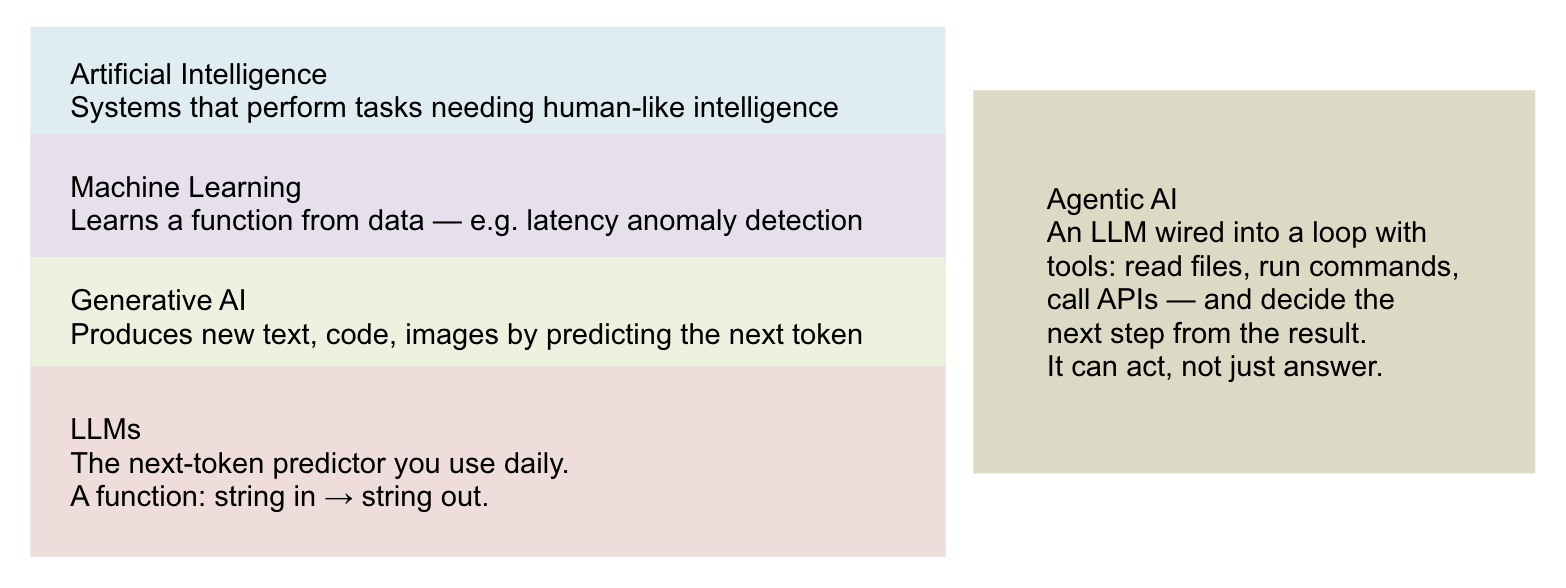

*The AI Landscape*

In [ ]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/Intro_to_Generative_AI_for_Engineers-01.png", width=800))
display(Markdown("*The AI Landscape*"))

## Machine Learning

* Machine learning is the umbrella technique where a system learns a function from data instead of being explicitly programmed.
* You give it labeled examples (supervised), unlabeled examples (unsupervised), or a feedback signal (reinforcement), and the model fits parameters that minimize error on those examples.
* For your team, the most common encounter with classic ML is in observability and platform tooling; anomaly detection on log volume, latency, or error-rate metrics.
* A model learns the normal shape of a service's traffic and flags points that deviate. It does not understand causes; it just notices that something looks unlike the past.

## Generative AI

* Generative AI is the subset of ML that produces new artifacts: text, code, images, audio. Large language models (LLMs) are the variant most engineering teams interact with daily.
* They predict the next token over and over until a stopping condition is met, conditioned on whatever input you give them.
* Generative systems do not look things up. They generate. If the most statistically plausible next tokens describe a function or API that does not exist, you get a fluent confident description of nothing. That failure mode is hallucination, and we will return to it.
    * Strength: compressing patterns across enormous amounts of code, prose, and documentation into a single fluent interface.
    * Weakness: it cannot tell you that it does not know.

## Agentic AI

* An agent is an LLM wired into a loop with tools. It can read files, run commands, call APIs, and decide what to do next based on the results. The same underlying generative model is now allowed to act, not just respond.
* For engineers, agentic systems unlock real automation: an agent can open a branch, edit files, run tests, and open a pull request. The risk profile changes accordingly.
* The question shifts from "is the answer correct?" to "what is this allowed to do, and how do I know when it is done?".

## AI vs Deterministic Code

* Deterministic code, given the same input, returns the same output. You can write a unit test that asserts equality and the test will pass for years. AI systems are probabilistic.
* The same prompt can produce different completions, and the same input can produce subtly different judgments.
* The practical rule: if you can write down the rules, write the code. If you cannot (summarize this log, suggest a refactor, draft a migration), AI earns its place. Mixing the two is fine, but knowing which layer you are in matters.

| Property | Deterministic Code | AI System |
| :------- | :----------------- | :-------- |
| Behaviour on same input | Identical | May vary |
| Failure mode | Throws or returns wrong value | Often returns a confident, plausible wrong value |
| Test strategy | Unit tests, equality assertions | Evals, rubrics, sampling, human review |
| Right home | Anything you can specify precisely | Tasks where "good enough" beats "impossible to specify" |

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# Key Terminology

Shared vocabulary so a code review comment that says "watch the context window" lands the same way across the team.

## Large Language Model (LLM)

* An LLM is a neural network trained on a very large corpus of text and code to predict the next token. "Large" refers to the parameter count (billions to trillions) and the training set size (trillions of tokens).
* Practically, an LLM is a function that takes a string and returns a string, where the output is sampled from a learned probability distribution.
* That is the whole interface. Everything else — chat windows, agents, code assistants — is plumbing around that single primitive.

## Tokens

* LLMs do not see characters or words. They see tokens, which are short sub-word units produced by a tokenizer. A rough heuristic for English: 1 token ≈ 4 characters, or 100 tokens ≈ 75 words. Code tokenizes denser, with curly braces, indentation, and identifiers each becoming their own tokens.
* Why this matters in practice:
    * API pricing is per token, input and output, and a 5000-line log file is a real cost.
    * The context window is measured in tokens, not lines.
    * Truncation happens at token boundaries, which is why pasted JSON can come back with a missing closing brace.

## Hallucination

* A hallucination is a confident, well-formed output that is not grounded in reality. The model is not lying; it is generating the most plausible continuation of your prompt. If your prompt asks for a function from a library that does not have that function, the model is happy to invent one.
* Slopsquatting:
    * Attackers register npm and PyPI packages with names that LLMs commonly hallucinate. An engineer who installs request-promise-utils on the model's suggestion gets a real package — with malware. Always verify package names against the registry before installing, especially for utility-sounding names you have never heard of.
* Mitigations: ask for citations, give the model the real docs in-context (see RAG), and refuse to merge code that uses an unfamiliar dependency without checking the registry yourself.

## Retrieval-Augmented Generation (RAG)

* RAG is the pattern of looking up relevant documents at query time and stuffing them into the prompt before generation. The model still generates, but now its plausible continuations are anchored to text you chose. RAG is the dominant remedy for hallucination on factual tasks.
* A typical engineering RAG flow:
    * Embed your docs (runbooks, ADRs, API specs) into a vector store.
    * At query time, embed the user's question and retrieve the top-k most similar chunks.
    * Prepend those chunks to the prompt with instructions like "answer only from the context above; if it is not there, say so".

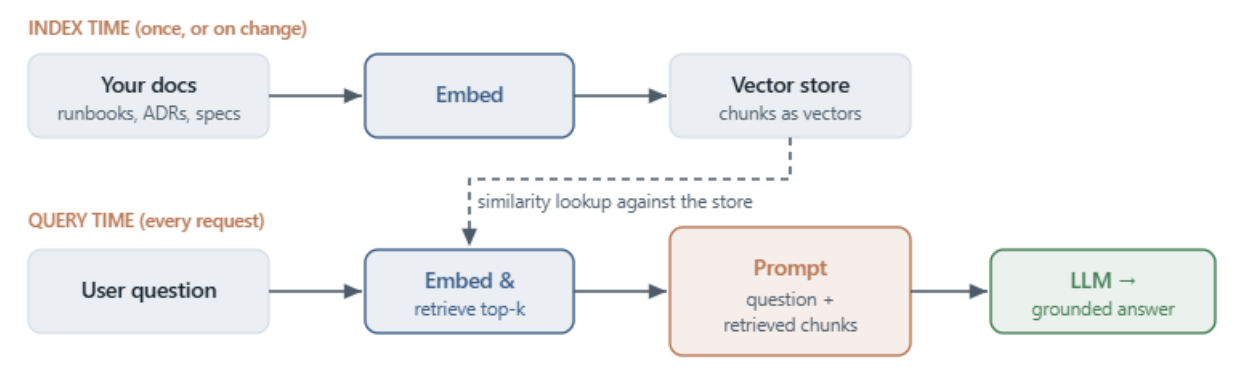

*RAG Reference Flow*

In [ ]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/Intro_to_Generative_AI_for_Engineers-02.png", width=800))
display(Markdown("*RAG Reference Flow*"))

* The model still generates — but its plausible continuations are now anchored to text you chose. Retrieval & chunking quality, not the model, decide the answer quality.
* RAG quality is mostly a chunking, retrieval, and prompting problem, not a model problem. Bad chunks in, bad answers out.

## Context Window

* The context window is the maximum number of tokens the model can attend to in one request, including the system prompt, conversation history, retrieved context, your question, and the generated answer. Older models had 4K or 8K windows; modern ones reach 200K to 1M tokens.
* Large does not mean unlimited or free. Two failure modes:
    * Lost in the middle: evidence buried in the middle of a long context is often ignored relative to evidence near the start or end. Put what matters at the edges.
    * Drift and cost: a long stale conversation costs more per turn and produces lower-quality answers than a fresh, focused one. Restart sessions for new tasks.

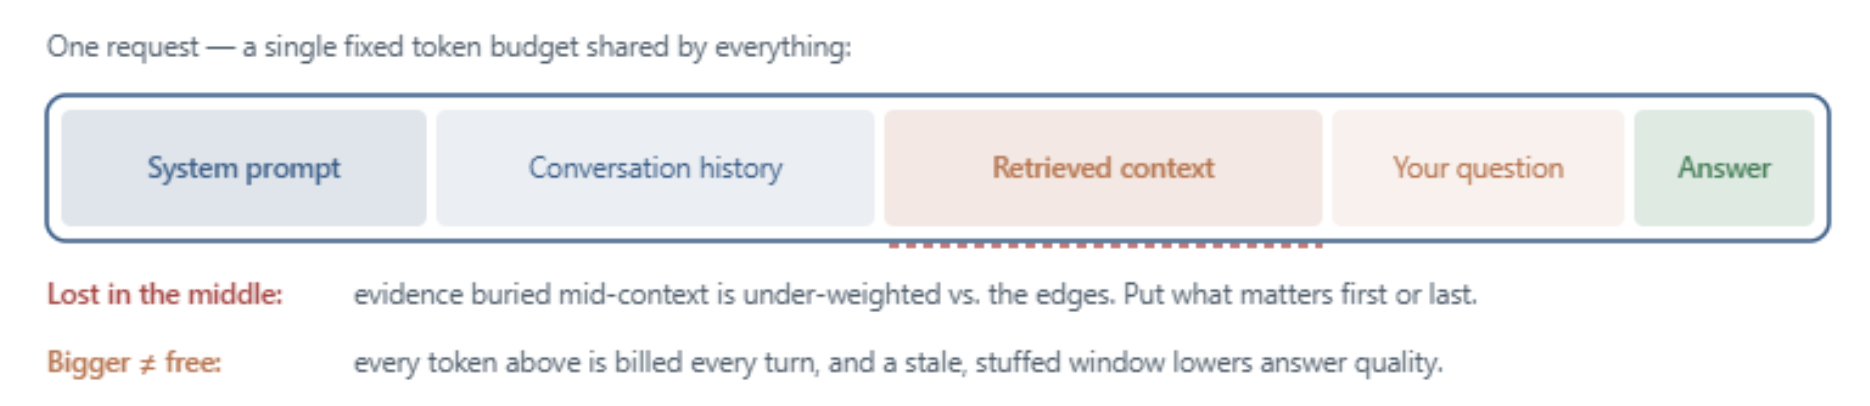

*What fills the Context Window*

In [ ]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/Intro_to_Generative_AI_for_Engineers-03.png", width=800))
display(Markdown("*What fills the Context Window*"))

"Context window" is one shared budget, measured in tokens, not lines. Trim to the relevant slice instead of pasting the whole file or the whole history.

## Temperature

* Temperature is a sampling parameter, typically 0 to 1 (some APIs allow upto 2). At temperature 0, the model picks the highest-probability next token every time, which makes output close to deterministic for short prompts. Higher temperatures sample more broadly, producing more varied, creative, and risky completions.
* If you do not control temperature directly (most chat UIs hide it), prompts that say "return only the JSON, no commentary" do similar work.

| Use case | Suggested temperature |
| :------- | :----------------- |
| Code generation, refactors, JSON output | 0 — 0.2 |
| Code explanation, doc drafting | 0.2 — 0.5 |
| Brainstorm, naming, alternative designs | 0.6 — 0.9 |

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# How LLMs Work

A working mental model of training and inference, plus the most useful frame engineers can borrow: a prompt is a function call.

## Pre-training

* Pre-training is the long, expensive phase where the model reads trillions of tokens of text and code and learns to predict the next token. Each prediction's error nudges billions of parameters slightly.
* After enough passes, the model has internalized a great deal of grammar, factual associations, code idioms, and reasoning patterns.
* Implications for engineers:
    * The model has a knowledge cut-off. Anything written after that date is invisible to it unless you bring it in via prompt or RAG.
    * Whatever was rare in training data is also rare in completions. Niche internal frameworks, custom DSLs, and small libraries get worse results.
    * Training data quality bounds model quality. Garbage in is still garbage out at scale.

## Fine-tuning and RLHF

After pre-training, the raw model is a fluent next-token predictor but not yet a useful assistant. Fine-tuning and Reinforcement Learning from Human Feedback (RLHF) shape it into one.

* Supervised fine-tuning: human-written examples of good responses are shown to the model so it learns the assistant style.

* RLHF: humans rank multiple candidate responses, and the model is rewarded for producing ones that rank higher. This is where "helpful, harmless, honest" behavior is shaped.

The result: a model that follows instructions, refuses certain requests, and prefers polite hedging when uncertain. None of this changes the underlying token prediction machinery; it tilts the probabilities.

## Inference

Inference is what happens when you send a prompt. The model encodes your text into tokens, runs them through its layers, and produces a probability distribution over the next token. It samples one, appends it, and repeats. There is no "thinking" ahead; each token is decided in turn.

This is why:
* Streaming exists — tokens are produced one at a time, so you can show them as they appear.
* Longer outputs cost more — each output token is another forward pass.
* Stop sequences and max-token limits matter — without them, the model decides when to stop, and that decision is itself probabilistic.

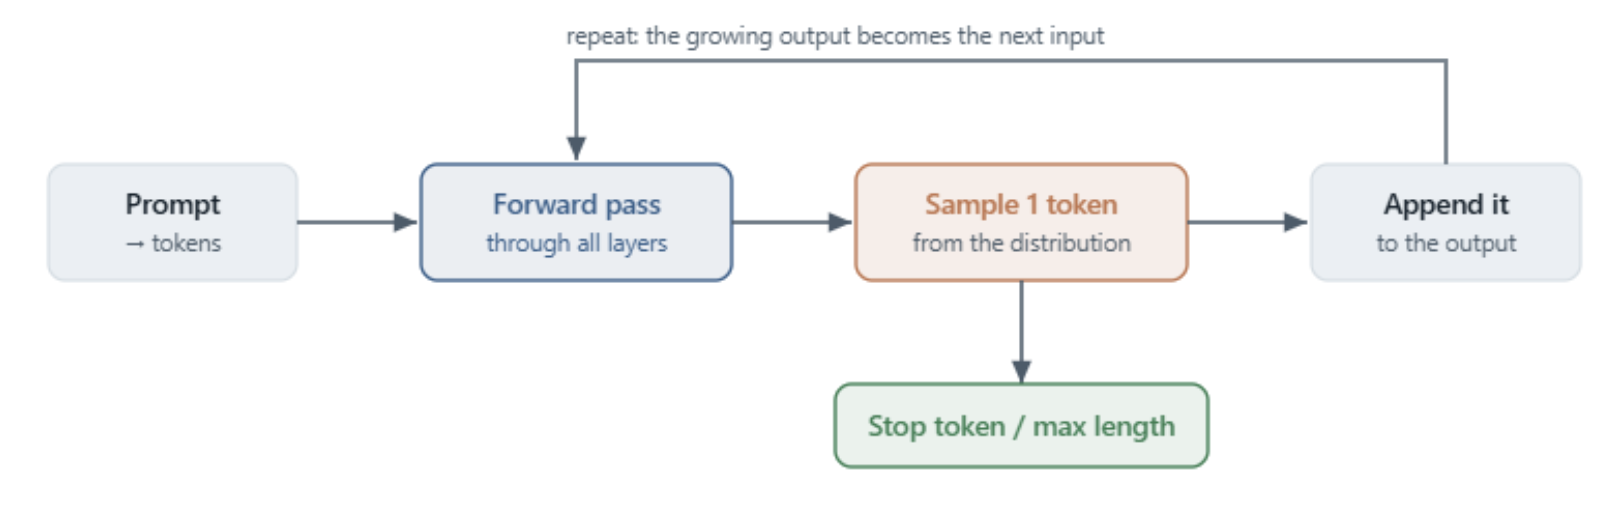

*Inference, one token at a time*

In [ ]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/Intro_to_Generative_AI_for_Engineers-04.png", width=800))
display(Markdown("*Inference, one token at a time*"))

There is no planning ahead — each token is decided in turn. This is why output streams, why longer outputs cost more (one forward pass per token), and why stop limits matter.

## Prompt as Function

* The single most useful mental model for engineers: treat a prompt like a function call.
* Every confusion an engineer has with LLMs maps back to one of these arguments (role, context, instruction, format) missing or vague. The model has no role, so it picks one. No context, so it invents. No format, so it gives prose when you wanted JSON. The fix is almost never "a better model". It is almost always "a better-specified call".
* This is the foundation of the RCTFV framework in Module 5.

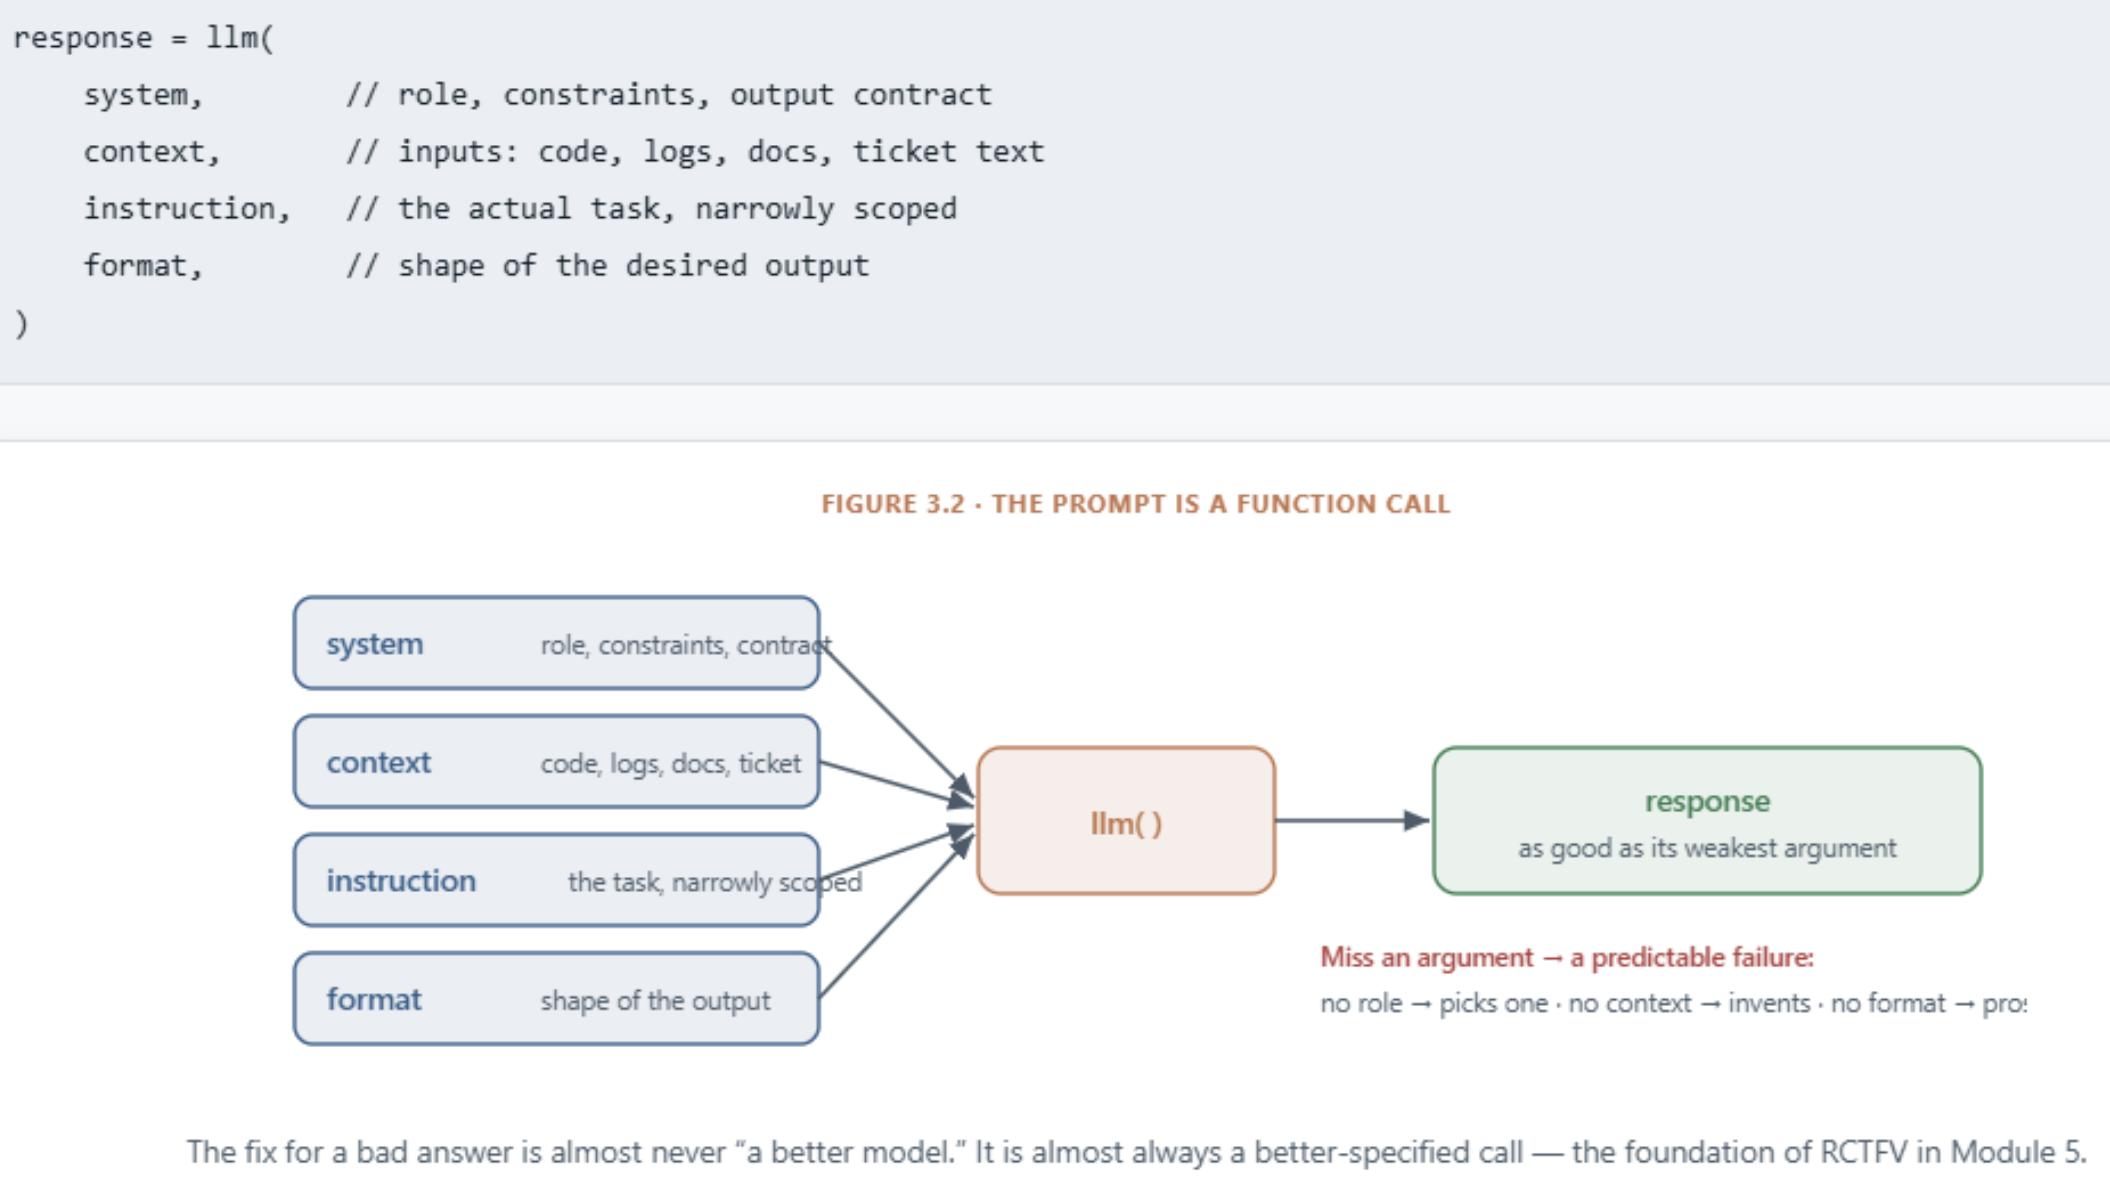

*The prompt is a function call*

In [ ]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/Intro_to_Generative_AI_for_Engineers-05.png", width=800))
display(Markdown("*The prompt is a function call*"))

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# Engineering Use Cases

Where AI earns its keep on a software team, with concrete examples. And, just as importantly, what it should not own.

## Code and Tests

* Strong fit. Generating a first draft of a function from a typed signature, scaffolding a parameterized test table, writing a quick CLI, translating a function from one language to another. The work feels like search-and-template, which is what LLMs are best at.
* Guardrails:
    * Always have the test run locally before trusting it. A well-formed test that asserts the wrong invariant is worse than no test.
    * For unfamiliar APIs, paste the real signature or docs into the prompt before asking for code.
    * Treat generated code as a starting point for review, not as a finished commit.

## Review and Debug

* Strong fit for a second-pair-of-eyes pass. Paste a diff or a function and ask for a list of concerns ranked by severity. Paste a stack trace and a snippet of relevant code and ask for likely causes.
* The model is good at surfacing patterns a tired human misses, like an unhandled error path or an obvious off-by-one.
* Caveats:
    * It will sometimes invent issues that do not exist. Treat its output as a checklist to verify, not a verdict.
    * For security review, prefer purpose-built tools and human review; an LLM can miss subtle, exploitable issues while flagging cosmetic ones.

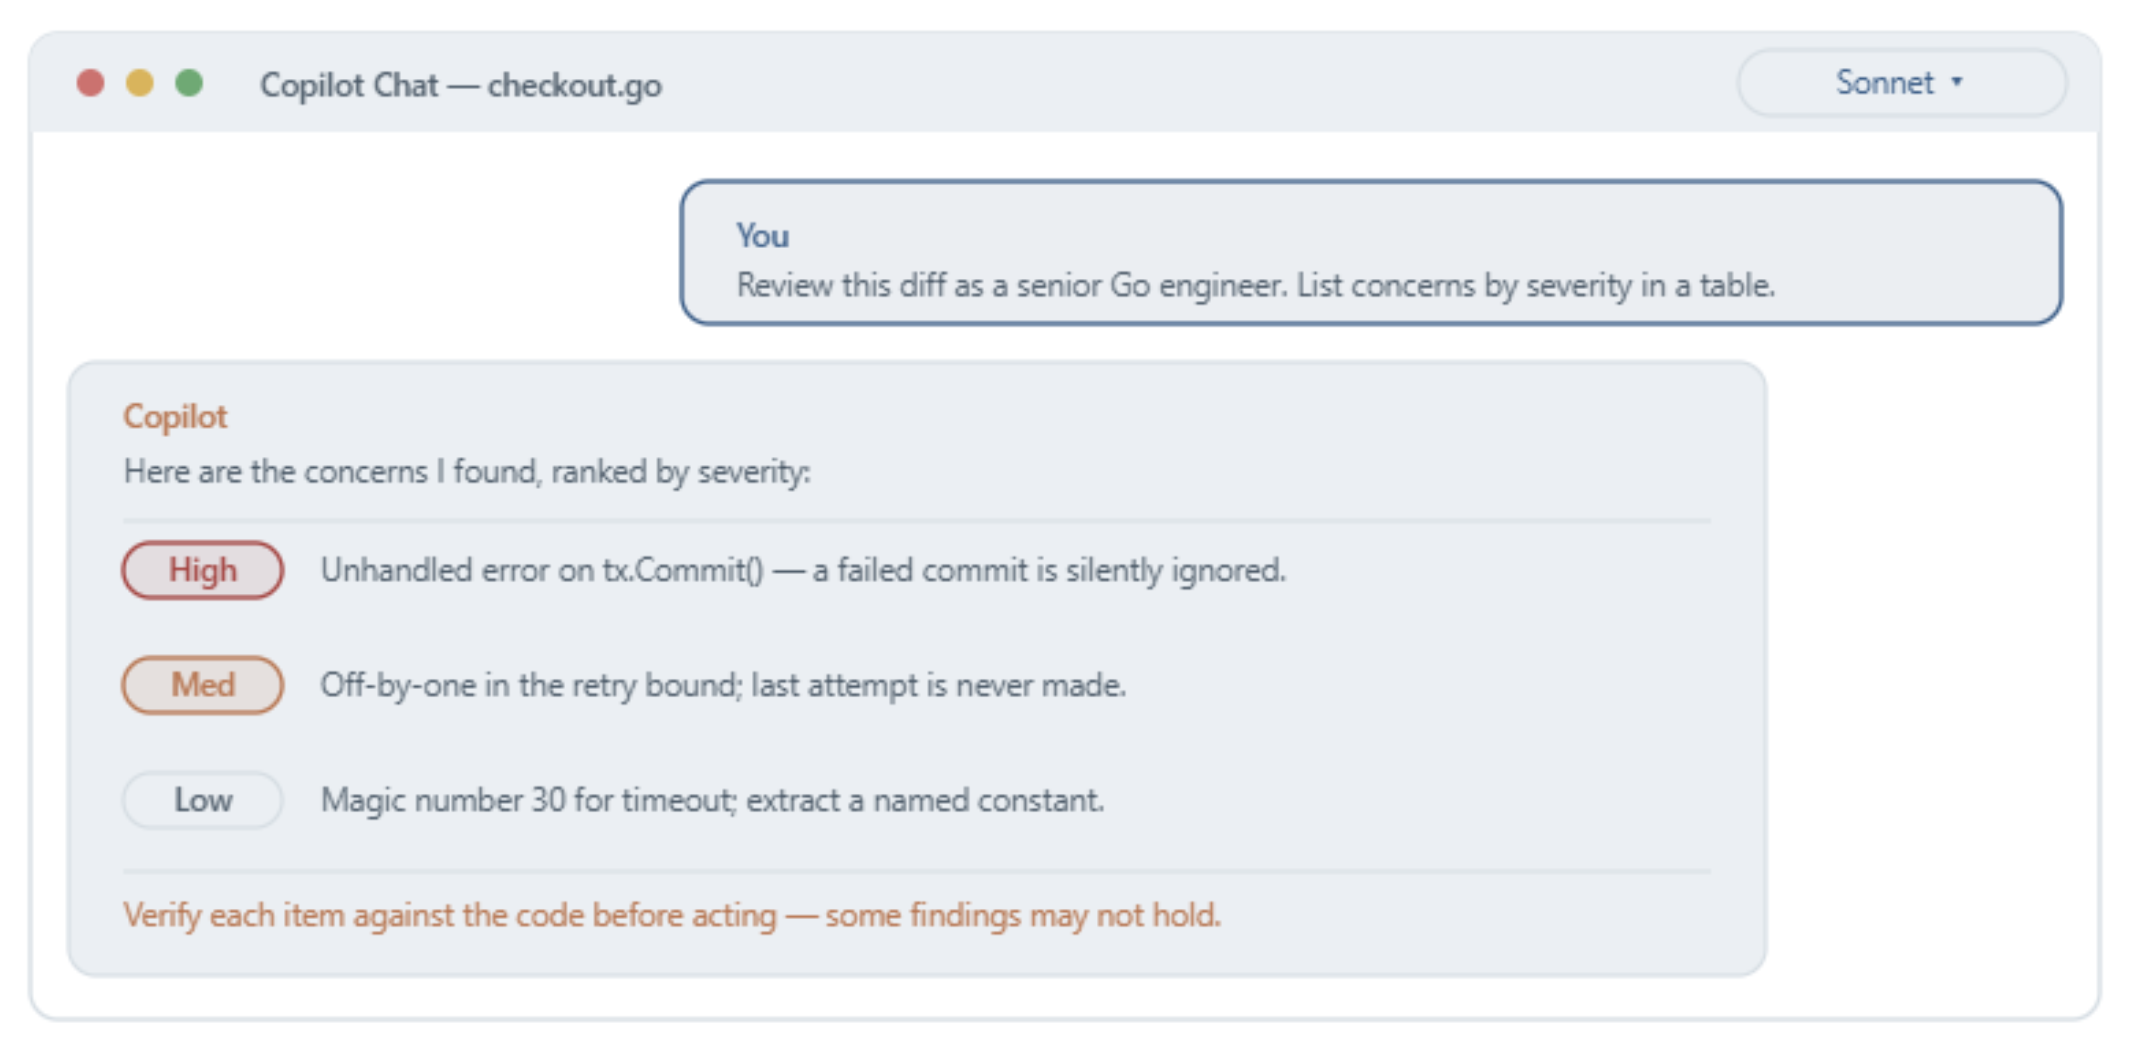

*A review prompt in an AI chat panel (Illustration)*

In [ ]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/Intro_to_Generative_AI_for_Engineers-06.png", width=800))
display(Markdown("*A review prompt in an AI chat panel (Illustration)*"))

A diff-and-severity request turns the assistant into a second pair of eyes — but its list is a checklist to verify, not a verdict. It can invent issues and miss real ones.

## Documentation

* Excellent fit for the boring half of docs work: turning a merged PR's diff and description into release notes, generating doc-comments from typed signatures, drafting a README outline from a directory listing, summarizing an incident timeline from a Slack thread for a postmortem.
* The high-value writing — design rationale, architecture decisions, the why — still benefits from human authorship. The model is good at the connective tissue, not the load-bearing decisions.

## Refactor and Migration

* Strong fit for repetitive, pattern-heavy migrations: renaming a deprecated API across many files, updating an import path, converting class components to hooks, moving from one logging library to another.
* Hand the model one example and ask for the rest, file by file, with a diff format you can apply.
* The harder a refactor is to specify, the worse the fit. "Untangle this 3000-line module" needs human judgment; "rename fooBar to foo_bar in these files" does not.

**Tip:** Ask for changes as a unified diff and apply them with `git apply`. Reviewing 30 small diffs is much easier than reviewing 30 full files, and the model is more disciplined when the format demands it.

## What AI Should Not Own

These belong to humans, with AI at most as a drafting aid:
* Production deploys: An agent can prepare a deploy, but the go/no-go and the rollback decision are human.
* Security review of changes that touch auth, secrets, or Personally Identifiable Information (PII): AI can flag candidates; humans approve.
* Customer-facing communication in incidents: Drafts are fine; the send button is human.
* Architecture and hiring decisions: Long-horizon, high context, irreversible. AI can challenge a draft; it should not author the call.
* Anything involving live secrets, customer PII, or unreleased financials in the prompt. See Module 6 => Data Safety & Responsible Use.

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# Prompt Engineering - the RCTFV Framework

A five-part contract for prompts that produce reviewable, useful output instead of confident sludge. Role, Context, Task, Format, Verification.

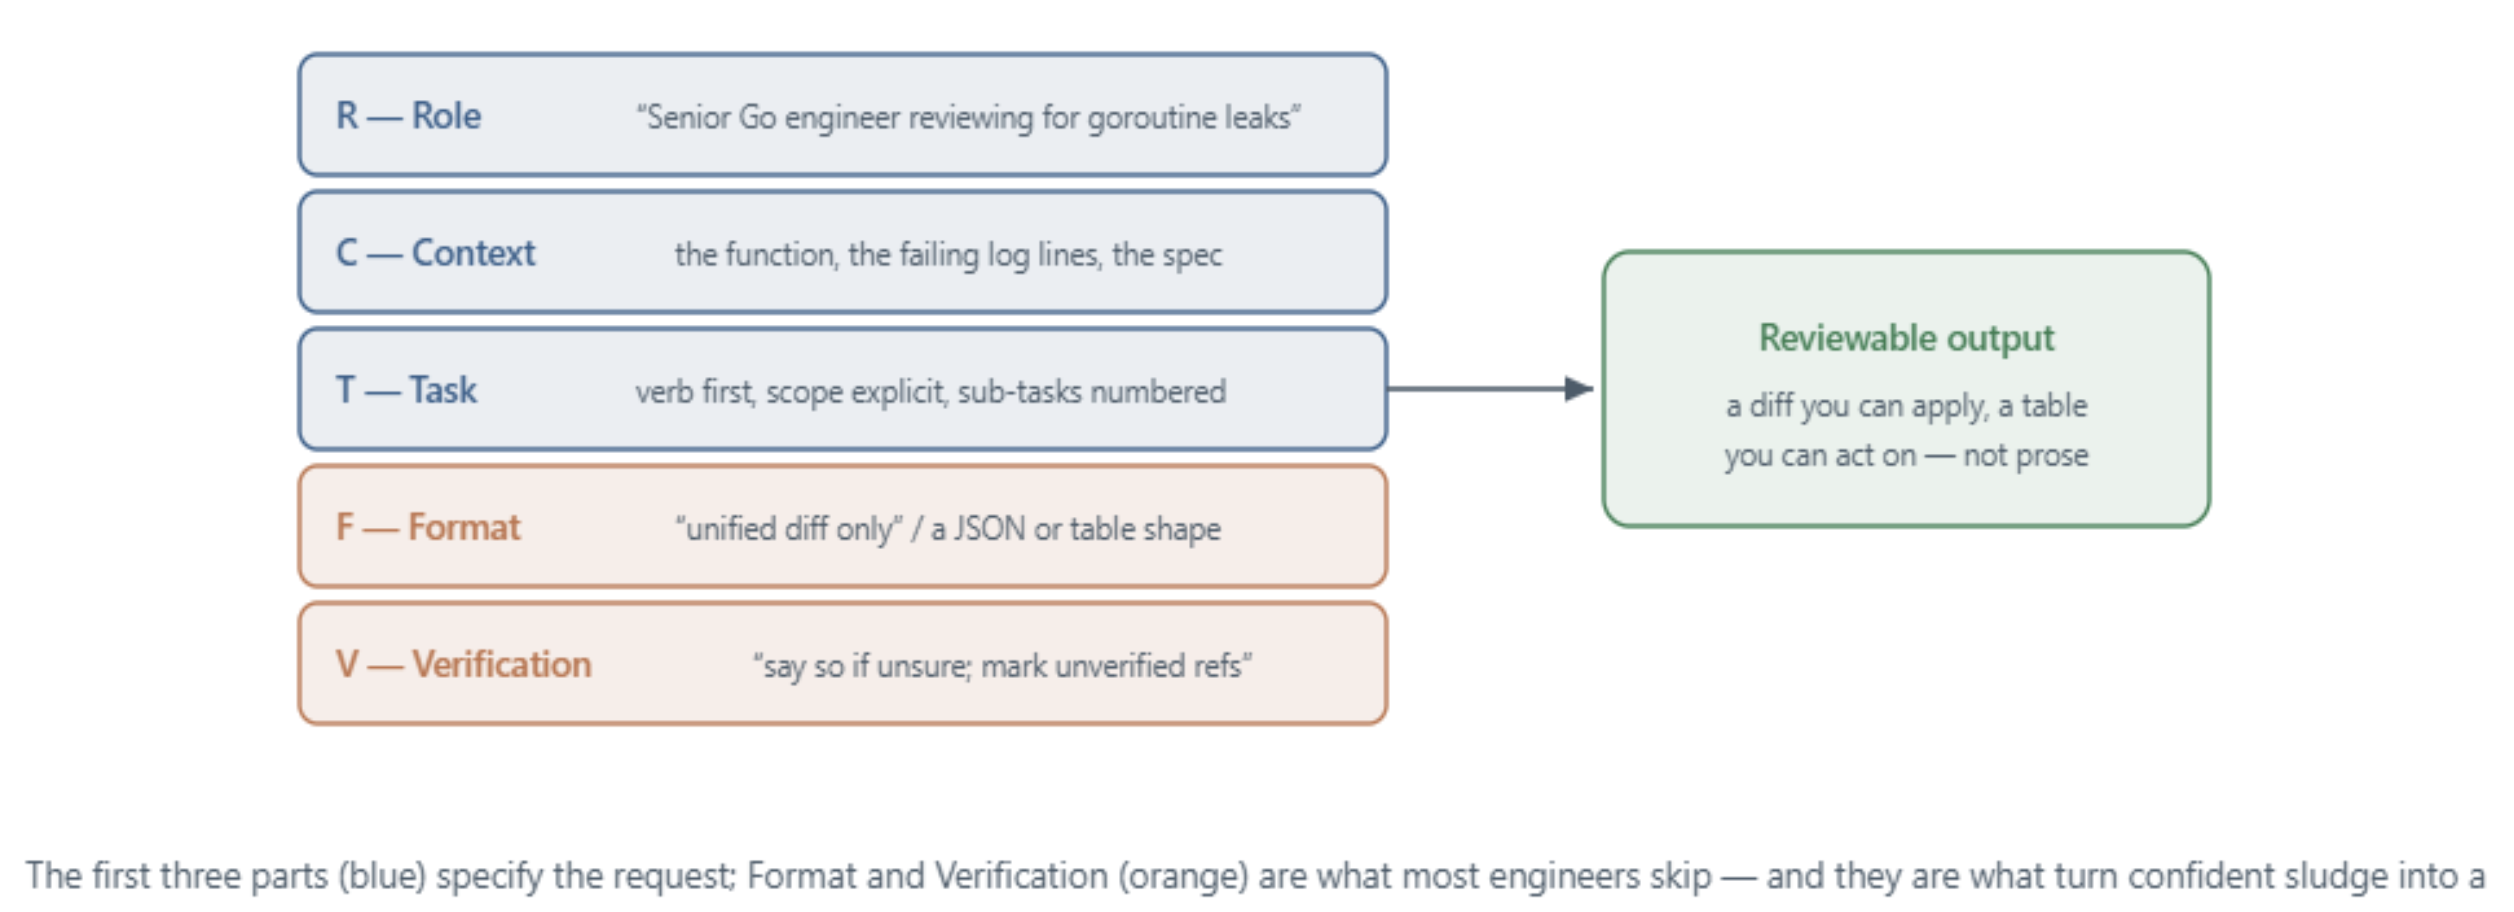

*The RCTFV Framework for Prompt Engineering*

In [ ]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/Intro_to_Generative_AI_for_Engineers-07.png", width=800))
display(Markdown("*The RCTFV Framework for Prompt Engineering*"))

## Role

* State the role you want the model to inhabit. This sets vocabulary, depth, and defaults. "Senior Go engineer reviewing this PR" produces a different response than "tutorial writer for a beginner".
* Role works best when it is specific and bounded. "A friendly assistant" is noise. "A reliability engineer who optimizes for blast radius and rollback safety" is signal.

## Context

* Give the model the inputs it needs to ground its answer: the function under review, the relevant log lines, the API spec, the failing test output. If the answer depends on something the model does not have, paste it in (subject to data-safety rules in Module 6).
* Two practical guidelines:
    * Mark each piece of context clearly: --- CODE ---, --- LOG ---, --- SPEC ---
    * Trim to what matters. A 200-line log noise-bomb is worse than the 20 lines around the failure.

## Task

* Say exactly what you want done. Verb first, scope explicit. "Refactor this function to remove the nested if and add a guard clause; do not change behavior or add features." A narrow, well-scoped task gets a sharp answer; "clean this up" gets an opinion-shaped object.
* If there are multiple sub-tasks, number them. The model handles enumerated tasks more reliably than buried-in-prose ones.

## Format

* State the shape of the output. This is the highest-leverage part of the prompt for engineers.
    * "Reply as a unified diff against the file above, nothing else."
    * "Return a JSON object with fields summary, issues (array of {severity, line, note}), and questions."
    * "Output a Markdown table with columns file, change, risk."
* A diff-shaped answer is reviewable in a glance. A paragraph-shaped one needs re-reading.

## Verification

* Tell the model how to handle uncertainty and how to flag its limits. This is what makes the difference between "confident slop" and "reviewable proposal".
    * "If you cannot determine X from the context above, say so explicitly instead of guessing."
    * "For every function or package you reference, mark it (verified from context) or (my prior knowledge, please verify)."
    * "List any assumptions you made at the end under Assumptions."
* Verification clauses do not eliminate hallucination, but they make it visible and easier to catch in review.

## Worked Example

A debug prompt that uses all five parts:

```markdown
ROLE: You are a senior backend engineer debugging a production latency regression.

CONTEXT:
--- CODE (handlers/checkout.go) ---
[paste relevant 40 lines]
--- LOG (last 60s before alert) ---
[paste 25 log lines around the alert]
--- DEPLOY ---
We shipped commit a1b2c3d 12 minutes before the alert. Diff touched only the order-validation path.

TASK:
1. List the three most likely causes of the p99 spike, ranked by probability given the evidence above.
2. For each, name the specific code path or query and the log line that supports the hypothesis.

FORMAT:
Return a Markdown table with columns: rank, hypothesis, supporting evidence (line ref), how to confirm.

VERIFICATION:
If the evidence does not support a hypothesis, say so rather than guessing.
Mark anything you inferred without direct support as (inferred).
Do not propose causes that require information not in the context above.
```

This kind of prompt produces a triage table you can act on, not a wall of speculative prose.

## Common Mistakes

* One-line prompts on multi-step problems. "Fix this" gets you what you ask for.
* Pasting whole files when 30 lines would do. The model gets distracted and you pay for the noise.
* No format contract. You spend the saved time reformatting prose.
* No verification clause. Hallucinated APIs go into the diff unchallenged.
* Treating chat as memory. Long sessions drift. Start a fresh chat for a new task and re-supply the context that matters.
* Asking for opinions on irreversible choices. Useful as a sparring partner; not a substitute for the call.

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# Data Safety & Responsible Use

A short durable framework for deciding what to paste into an AI tool and what to keep out, plus the habits that make it automatic.

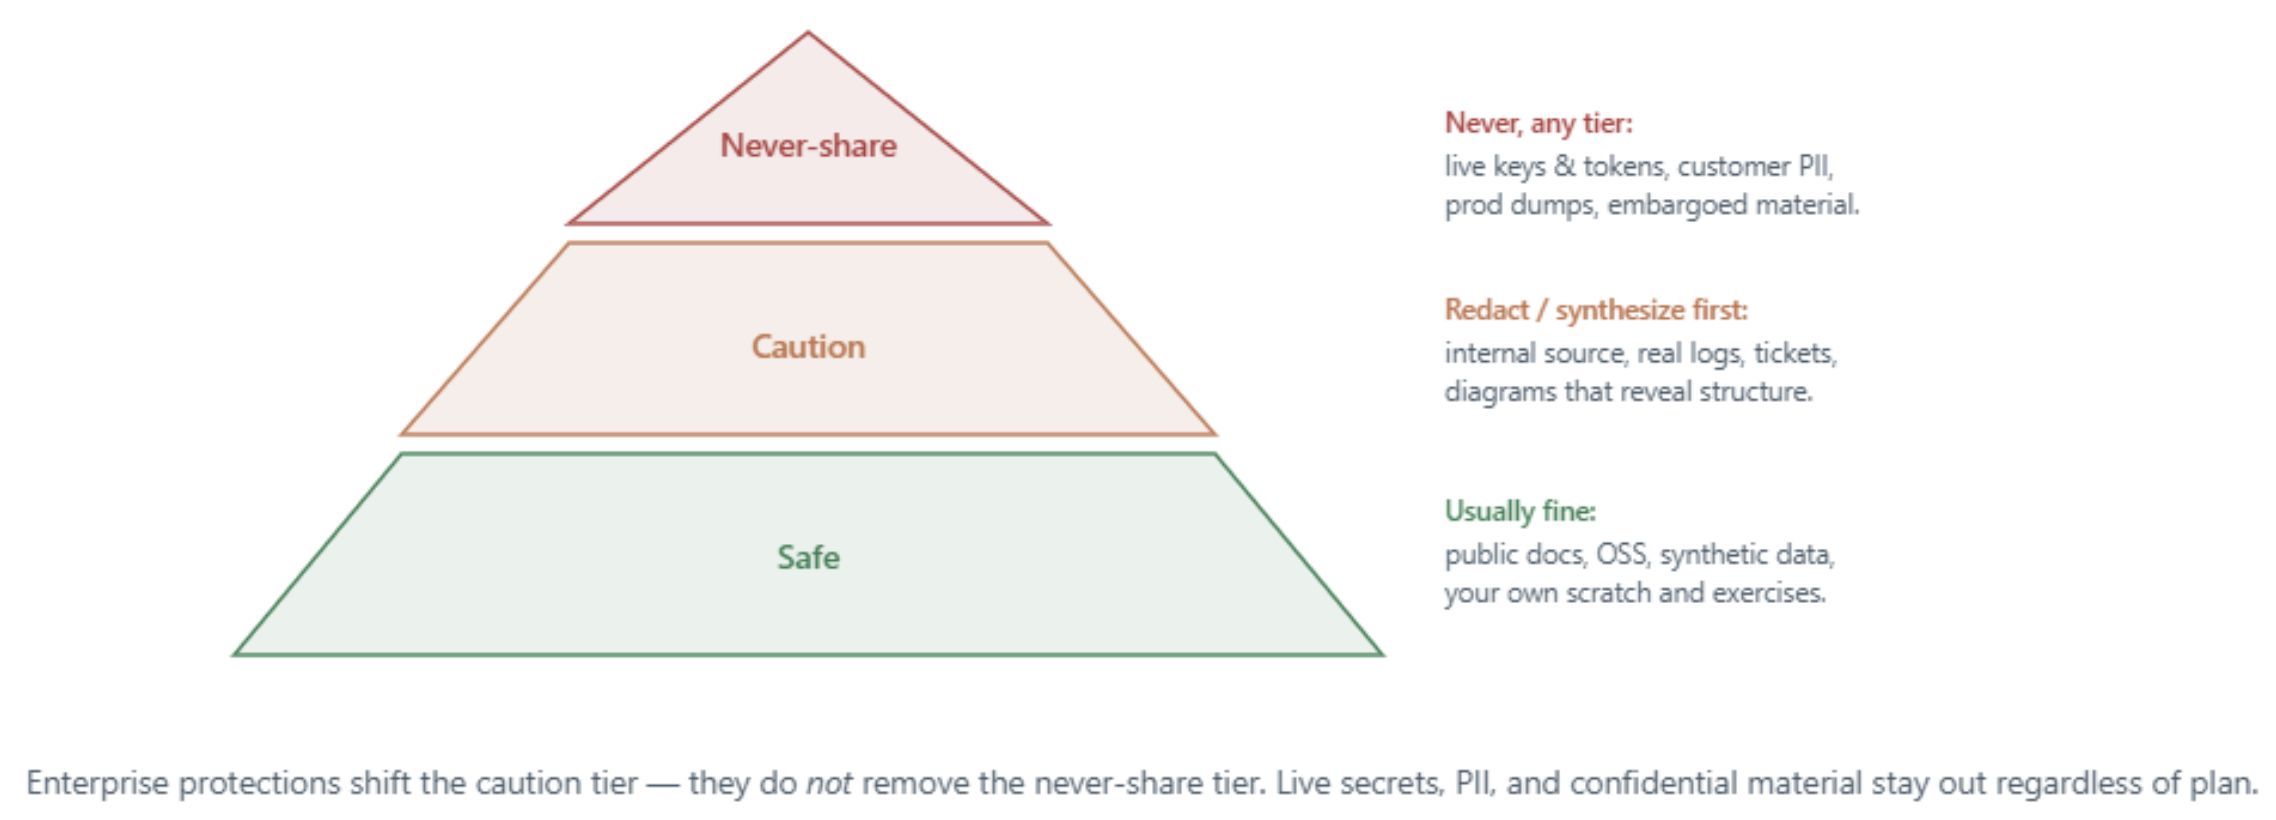

*The three data-safety tiers*

In [ ]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/Intro_to_Generative_AI_for_Engineers-08.png", width=1000))
display(Markdown("*The three data-safety tiers*"))

## Never-share Tier

Do not paste these into any AI tool, including ones you believe are private, unless your company has an explicit, documented carve-out:

* Live credentials of any kind: API keys, OAuth tokens, database passwords, SSH keys, signed JWTs (JSON Web Tokens).

* Customer PII: names paired with emails, addresses, phone numbers, government IDs, health info, financial accounts.

* Unreleased financials, M&A (Mergers & Acquisitions) material, board content, or anything under embargo.

* Production data dumps, even "just for debugging".

* Source code from systems that policy or contract designates as confidential.

**Reflex:** If you catch yourself thinking "I'll just paste the real secret to make it concrete" stop. Replace with REDACTED-API-KEY or a fake. The model does not need a real key; it just needs the shape.

## Caution Tier

Use judgment, and prefer redacted or synthetic versions:

* Internal source code that is not labeled confidential but is not public either.

* Real log lines, stack traces, or error messages that may contain user identifiers or internal hostnames.

* Architecture diagrams or system descriptions that reveal internal structure beyond what is already public.

* Tickets and bug reports that may mention specific customers or partners.

**A simple test:** would you be comfortable if this exact test appeared in a public dataset two years from now? If not, scrub it before pasting.

## Safe Tier

Almost always fine:

* Public documentation, open-source code, and standard language or framework questions.

* Synthetic or fake data that resembles your real data's shape without containing real values.

* Your own scratch code, learning exercises, and personal experimentation.

* Internal questions that contain no specific identifiers, secrets or proprietary structure.

Most engineering work fits here once you have built the habit of redacting and shaping inputs.

## Enterprise Protections

Enterprise tiers of AI tools typically offer:

* No training on your data: Inputs are not added to future training sets.

* Tenant isolation: Your data is not pooled with other customers' data at the model level.

* Audit logging: Prompts and responses are retrievable for compliance review.

* Retention controls: Time-to-live on stored conversations.

* SSO (Single Sign-On) and DLP (Data Loss Prevention) integration: Identity-aware access and data loss prevention scanning.

These protections shift the Caution tier, but they do not eliminate it. The Never-share tier still applies; enterprise mode is not a license to paste raw credentials.

## Daily Habit Checklist

Before pasting anything into an AI tool, run this in your head:

* Is it a secret? Keys, tokens, passwords, certs. If yes, redact.

* Is it identifiable? Real names, emails, IDs. If yes, replace with placeholders.

* Is it internal-confidential? Embargo, M&A, unreleased plans. If yes, do not paste.

* Could the shape alone leak something? A schema, a private API path, an internal hostname. If yes, generalize.

* Am I in the right tool? Personal account for personal code; enterprise tool for work.

The whole list takes ten seconds once it is a habit. The cost of skipping it is paid for years.

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# Model Choice & Cost

The same task can cost ten cents or ten dollars depending on which model you pick and which tool wraps it. A working framework for matching model tier to task, and for understanding how Copilot, Cursor, Claude Code, and raw API access reshape the bill.

## Model Tier Framework

* Almost every provider ships a tiered family of models with the same general shape: a small/fast tier, a balanced standard tier, and a premium reasoning tier. Pricing scales with capability and with the cost of running inference.
* The gap between the cheapest and most expensive model in a family is typically 10x to 30x per token.
* Skill is matching model to task, not reaching for the most capable on reflex. A team that defaults to the premium tier for every completion pays roughly 10x more than a team that uses the small tier for routine work and reserves premium for the hard cases.

**One sentence to remember:** Pick the smallest model that solves the task. Step up when it stops working, not before.

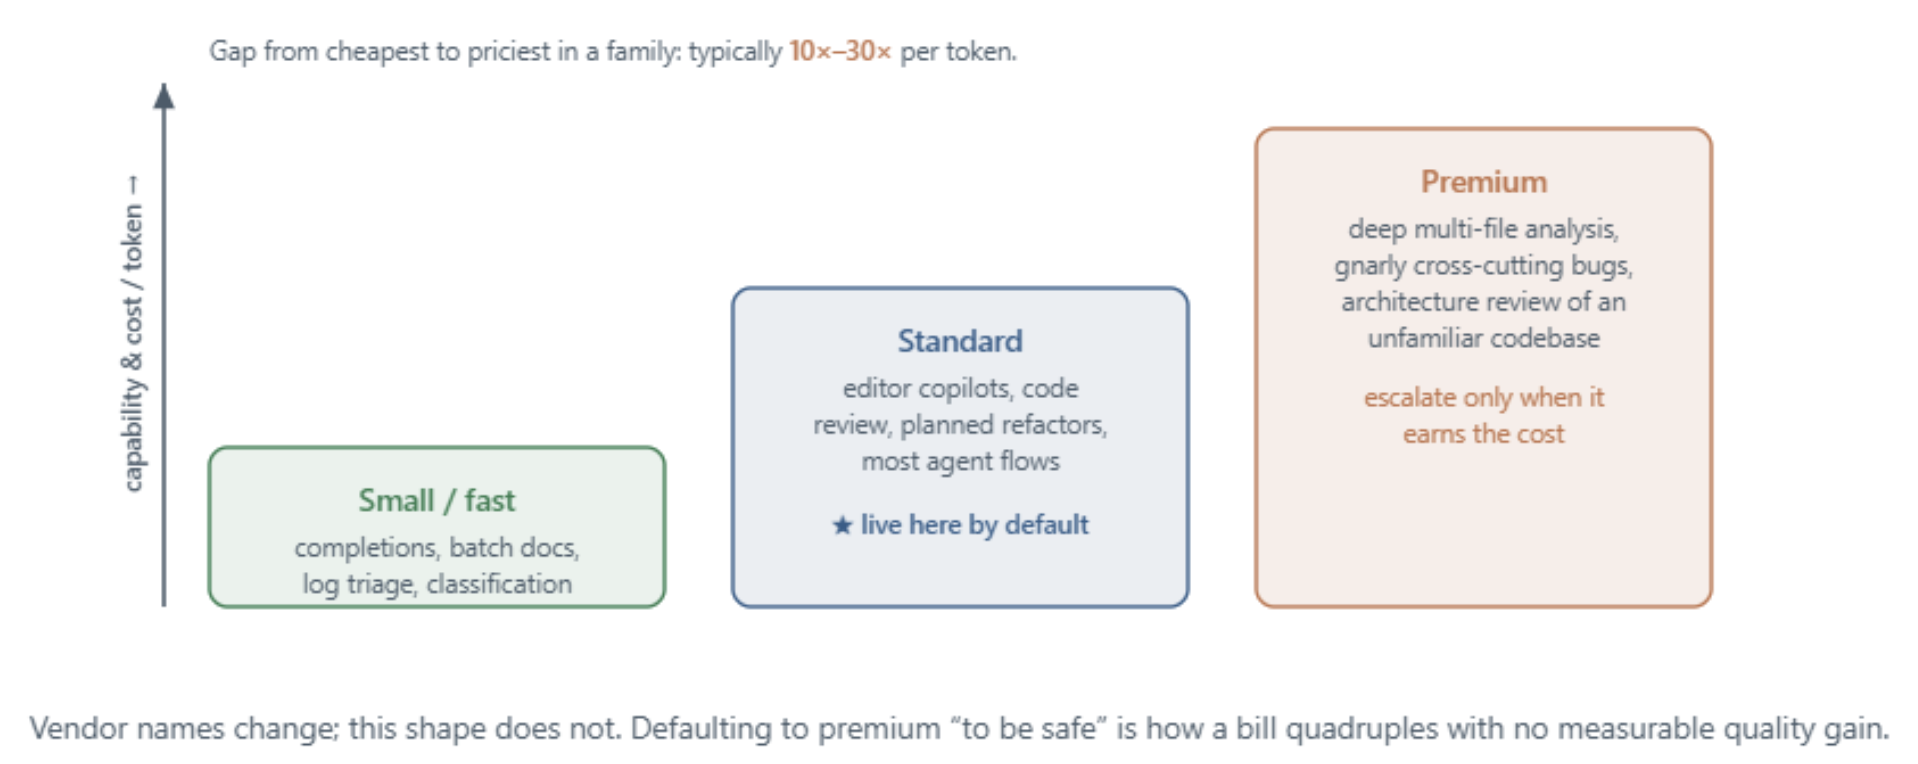

*The Model Tier Ladder*

In [ ]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/Intro_to_Generative_AI_for_Engineers-09.png", width=800))
display(Markdown("*The Model Tier Ladder*"))

## Anthropic Models

**Anthropic: Haiku, Sonnet, Opus**

| Tier | What it is good at | Typical engineering use |
| :--- | :----------------- | :---------------------- |
| Haiku | Fast, inexpensive, very capable for routine tasks | High-volume code completion, single-file refactors, doc-comment generation, log triage, summarization at scale, classification |
| Sonnet | Balanced reasoning and tool use; strong for agentic flows | Default for editor copilots, multi-step code review, refactors that need a plan, agents that orchestrate sub-agents and call tools |
| Opus | Premium reasoning over long context and hard problems | Multi-file refactors, deep architectural review, debugging across unfamiliar large codebases, analysis that earns the cost |

Prompt caching applies across all three: if you reuse a large prompt prefix (system instructions, repo context, framework docs), cached tokens are billed at a fraction of standard input cost. Put the variable part of your prompt last so the front stays cache-eligible.

## OpenAI & Other Providers

* OpenAI ships a similar tier pattern: a fast/cheap variant (GPT mini and nano lines), a standard variant (the flagship GPT generation), and distinct reasoning-focused variants that trade higher cost for stronger structured reasoning.

* Code-specialized variants (Codex-style) are tuned for code generation and may have separate pricing from general chat models.

* Other providers follow the same shape:
    * Google Gemini: Flash (small/fast), Pro (standard), and a reasoning-focused Pro mode.
    * Meta Llama, Mistral, DeepSeek, Qwen: open-weights families with small / standard / large variants; hosted by third parties at varied pricing.

* The principle holds across providers: cheap fast model for most tasks, standard for reasoning or agentic flow, premium for the hard cases. Pricing changes often. Treat the tier framework as durable; treat any dollar figure as a snapshot.

## How Tooling Reshapes Cost

The same underlying model can cost very different amounts depending on how you access it.

| Tool | Pricing model | What you actually pay for |
| :--- | :------------ | :------------------------ |
| GitHub Copilot | Usage-based AI credits (per-seat plan + included monthly credits) | Inline completions are free on paid plans; chat, agent mode, code review, and the CLI draw from a monthly AI-credit allowance. A built-in model picker lets you choose the model (Claude, GPT, or Gemini); the free and auto tiers pick for you. |
| Cursor | Subscription + premium request quota | Standard completions are bundled. Premium model calls (top-tier from Anthropic or OpenAI) count against a monthly cap. Picking premium for every request burns the quota fast. |
| Claude Code (CLI/desktop) | Subscription (Max plans) or usage based | Either bundled into a flat plan or pay-per-token at API rates. |
| ChatGPT (Plus / Team / Enterprise) | Flat subscription | Bundled messages; access to specific models gated by plan tier. |
| Direct API access | Pay per token, input and output billed separately | Exact metered usage. Cheapest for predictable, well-prompted workloads; most expensive for "paste the whole repo" habits. |
| IDE plugins (Continue, Cline, RooCode etc.) | Bring-your-own API key | Direct API costs with the plugin routing requests. You see the bill clearly. |

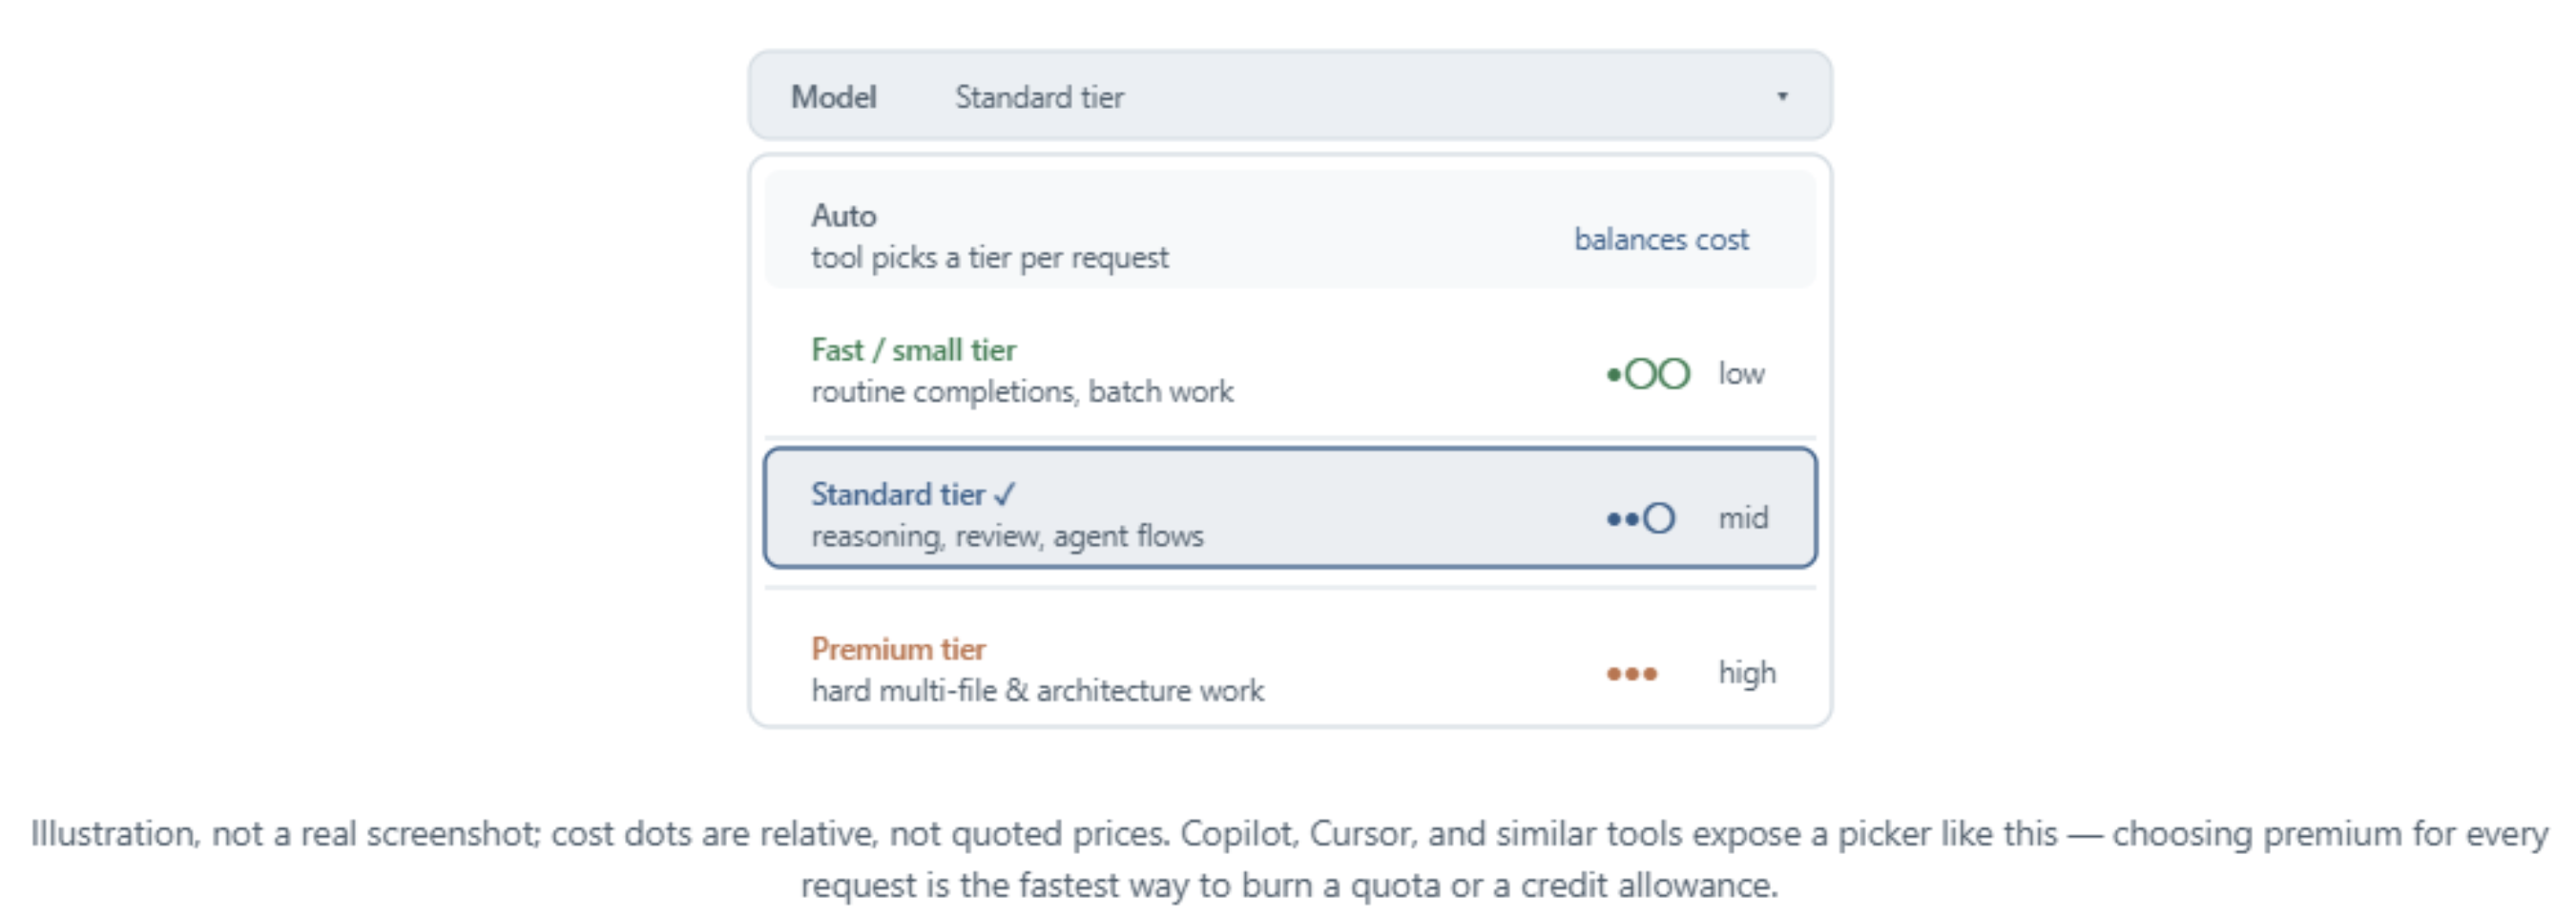

*The In-Tool Model Picker (Illustration)*

In [ ]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/Intro_to_Generative_AI_for_Engineers-10.png", width=800))
display(Markdown("*The In-Tool Model Picker (Illustration)*"))

Three practical implications:

* Subscription tools bundle model access. Copilot auto-selects the model for inline completions, but its model picker lets you choose per request for chat, agent, and review work — and different models spend credits at different rates.

* Quota-based tools punish careless picks. If Cursor exposes a model picker, using the premium tier for routine completions is the single fastest way to exhaust your monthly quota.

* Agentic tools amplify cost. A chat call is one round trip. An agent that runs 30 tool calls per task uses roughly 30x the tokens. Sometimes worth it, often not.

## Picking the Right Model for the Job

A practical default ladder:

* Try the small/fast tier first for routine tasks — completions, simple refactors, doc generation, log summarization. If the answer is good enough, you are done at a fraction of the cost.

* Step up to the standard tier when the task involves real reasoning, multi-step refactors, agent flows, or when small-tier output is clearly sloppy.

* Reach for the premium tier when the task is genuinely hard: deep multi-file analysis, gnarly cross-cutting bugs, architectural review of an unfamiliar large codebase.

A useful reverse-default: most engineers should live at the standard tier, drop to small for batch and throughput tasks, and escalate to premium only for the hard cases. Defaulting to the most expensive model "just to be safe" is how API bills quadruple without measurable quality gains.

| Task | Suggested tier |
| :--- | :------------- |
| Doc-comment generation across many files | Small/fast |
| Single-file refactor against a known framework | Small/fast or Standard |
| Code review of a PR diff | Standard |
| Multi-file rename or library migration | Standard |
| Debug a gnarly cross-service issue with logs and code | Premium |
| Architectural review of an unfamiliar large codebase | Premium |
| Agent that plans, edits, and runs tests over many steps | Standard (sometimes premium on the planning step) |

## Practical Cost Discipline

A short set of habits that keep AI spend sane regardless of which tool or model you use:

* Trim context before pasting. A 4000-token file pasted to ask about one function is billed every turn. Paste the function and its immediate callers, not the file.

* Use prompt caching where available. Static prompt prefixes cache and are billed at a fraction of standard input cost. Put the variable part last.

* Start fresh sessions for new tasks. Long sessions accumulate context that is billed on every turn and rarely improves answer quality.

* Constrain output length. "Return a unified diff, nothing else" costs much less than "explain in detail and return the changes".

* Watch agent loops. Set step limits. An agent that loops for 80 tool calls on a three-step task is a bug, not a feature.

* Know your team's plan. Seat-based plans have predictable monthly cost; API access is metered. Choose the access model that matches your workload.

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# Assessment

Please try the [**Intro to Generative AI for Engineers: Assessment**](https://github.com/ancilcleetus/AI-Learning-Lab/blob/main/Generative-AI/Intro-to-Generative-AI-for-Engineers/Intro-to-Generative-AI-for-Engineers-Assessment.html).

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# References

- **Photon University: AI Basics for Engineers Course**

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)